# Lab 01 : ✅ Vérifiez votre environnement de ML

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/atouammi/Formation_CNN_API_Docker_Module4/blob/main/Labs/01_test_notebook.ipynb)

Bienvenue ! Ce notebook effectue quelques vérifications de base pour s'assurer que votre environnement de machine learning est correctement installé. Il compare vos versions de Python et des bibliothèques à celles indiquées dans le fichier requirements.txt.

Exécutez simplement les cellules une par une. Un ✅ signifie que la version correspond ; un ⚠️ signale un écart. Sur Google Colab, quelques ⚠️ sont normaux : Colab fournit ses propres versions, et les notebooks fonctionnent quand même.


### 🧠 Petit rappel sur les notebooks Jupyter

Les notebooks Jupyter sont un environnement de programmation interactif qui réunit du code, du texte et des visualisations dans un même document. Tout au long de ce cours, vous utiliserez des notebooks pour :

- Lire des consignes et des explications (comme celle-ci !)

- Exécuter et modifier du code Python

- Explorer des données à l'aide de graphiques et de visualisations interactives

👉 Chaque bloc de ce notebook est une **cellule**. Certaines contiennent du **texte**, d'autres du **code**. Cliquez sur une cellule et exécutez-la avec Maj + Entrée ou avec le bouton ▶️ **Run** de la barre d'outils.

In [1]:
# ⚙️ Configuration – exécutez cette cellule en premier.
# - Sur Google Colab : récupère les fichiers du cours (plotting_utils/, assets/, requirements.txt)
#   et installe ce qui manque.
# - En local (VS Code) : rien à faire, l'environnement est déjà installé avec requirements.txt.
import os, sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO_DIR = "/content/Formation_CNN_API_Docker_Module4"
    if not os.path.exists(REPO_DIR):
        !git clone -q https://github.com/atouammi/Formation_CNN_API_Docker_Module4.git {REPO_DIR}
    %cd {REPO_DIR}/Labs

if "." not in sys.path:
    sys.path.append(".")
print("Environnement :", "Google Colab" if IN_COLAB else "local")

Environnement : local


### 🐍 Vérifier la version de Python

In [2]:
# Note pédagogique : cette cellule vérifie que la version de Python est compatible avec le cours.

import sys
print("Version de Python :", sys.version)

major, minor = sys.version_info[:2]
if (major, minor) in [(3, 11), (3, 12)]:
    print(f"✅ Python {major}.{minor} : compatible avec le cours.")
else:
    print(f"⚠️ Python {major}.{minor} : le cours est prévu pour Python 3.11 ou 3.12. Certaines bibliothèques pourraient ne pas s'installer.")

Version de Python : 3.12.1 (v3.12.1:2305ca5144, Dec  7 2023, 17:23:38) [Clang 13.0.0 (clang-1300.0.29.30)]
✅ Python 3.12 : compatible avec le cours.


### 📦 Vérifier les versions des bibliothèques (d'après requirements.txt)

In [3]:
# Note pédagogique : cette cellule lit la liste des dépendances du projet pour comparer l'environnement aux exigences du cours.

import re

def get_required_versions_from_text(txt):
    required_versions = {}
    for line in txt.splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        if "~=" in line or "==" in line:  # seules les versions fixées sont contrôlées (pas les minimums >=)
            package = re.split(r"[<>=~]", line)[0]
            match = re.search(r"\d+\.\d+", line)
            if match:
                required_versions[package] = match.group()
    return required_versions

# 📄 Charger le requirements.txt du projet (à la racine, un niveau au-dessus de Labs/)
from pathlib import Path
req_path = next(p for p in [Path("../requirements.txt"), Path("requirements.txt")] if p.exists())
requirements_txt = req_path.read_text()

required_versions = get_required_versions_from_text(requirements_txt)

In [4]:
# Note pédagogique : cette cellule compare les versions installées aux versions du cours, sans bloquer en cas d'écart.

import importlib.metadata as metadata

for pkg, required in required_versions.items():
    try:
        version = metadata.version(pkg)
    except metadata.PackageNotFoundError:
        print(f"⚠️ {pkg} : non installé (attendu : {required}.x)")
        continue
    status = "✅" if version.startswith(required) else "⚠️"
    print(f"{status} {pkg} : {version} (attendu : {required}.x)")

✅ numpy : 2.0.2 (attendu : 2.0.x)
✅ pandas : 2.2.3 (attendu : 2.2.x)
✅ scipy : 1.16.3 (attendu : 1.16.x)
✅ scikit-learn : 1.6.1 (attendu : 1.6.x)
✅ tensorflow : 2.18.1 (attendu : 2.18.x)
✅ torch : 2.6.0 (attendu : 2.6.x)
✅ ultralytics : 8.3.253 (attendu : 8.3.x)
✅ matplotlib : 3.10.9 (attendu : 3.10.x)
✅ plotly : 5.24.1 (attendu : 5.24.x)
✅ ipywidgets : 7.7.5 (attendu : 7.7.x)


### 📈 Test rapide d'un graphique

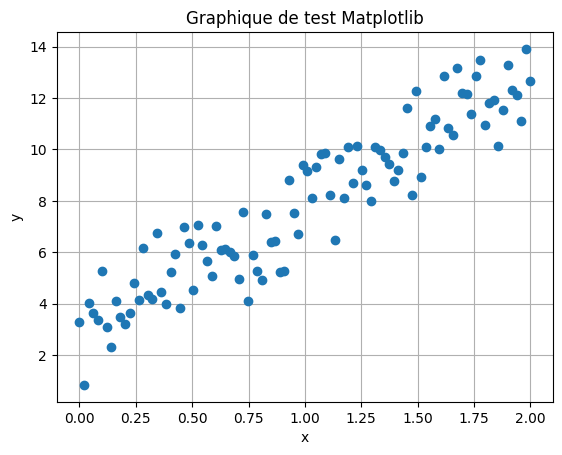

In [5]:
# Note pédagogique : ce petit exemple NumPy + Matplotlib vérifie que le calcul numérique et l'affichage des graphiques fonctionnent.

import numpy as np
import matplotlib.pyplot as plt

# Générer des données synthétiques
x = np.linspace(0, 2, 100)
y = 3 + 5 * x + np.random.randn(100)

plt.plot(x, y, 'o')
plt.title("Graphique de test Matplotlib")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()

### ✅ Tout est bon !

Si toutes les cellules se sont exécutées sans erreur, votre environnement est prêt ! 🎉

En local, si vous voyez des ⚠️, réinstallez l'environnement avec `pip install -r requirements.txt`. Sur Colab, `ultralytics` apparaît comme non installé : c'est normal, il est installé automatiquement dans le lab 05.

Vous pouvez maintenant attaquer les notebooks pratiques : régression, réseaux de neurones, détection d'objets… Amusez-vous bien !